# Climate Transition Risk in a Corporate Bond Portfolio: NGFS Phase 5 Scenarios, Reported Emissions and an ML Spread-to-PD Model

Supervisors now ask lenders a concrete question: if carbon prices rise and fossil-fuel demand falls, which borrowers get into trouble, and how much does the portfolio lose? Answering it means linking each issuer's real emissions to a scenario and then to its credit quality. This notebook does that, issuer by issuer, for a real U.S. corporate bond portfolio.

**What it does.** It stress-tests a real U.S. corporate bond portfolio for **climate transition risk**. The portfolio is the non-financial issuers held by the two largest investment-grade and high-yield corporate bond ETFs: about 700 issuers, of which about 400 have complete statements and are modelled.

**Data, issuer by issuer:**

- financial statements from SEC XBRL filings;
- **reported direct greenhouse-gas emissions** from the EPA Greenhouse Gas Reporting Program, allocated to parent companies by ownership share;
- market spreads from the bond holdings.

**Model.** A monotonic **LightGBM** model learns how the market prices credit from fundamentals: leverage, interest coverage, margins, size and sector. It maps any balance sheet to a spread and a default probability.

**Scenarios.** The seven **NGFS Phase 5** scenarios, from two integrated assessment models (GCAM and REMIND), give U.S. carbon prices, sector emission paths and energy demand to 2050. Each issuer's EBITDA is hit by three things:

- carbon costs on its remaining emissions;
- abatement costs;
- lower demand for fossil energy, net of cost pass-through.

The ML model re-prices the stressed balance sheet. The output is the PD migration, the expected loss and the credit VaR of the portfolio by scenario and horizon, with sector and issuer attribution.

**Sources.** NGFS Phase 5 Scenario Explorer (IIASA), EPA GHGRP via Envirofacts, SEC EDGAR XBRL frames, iShares LQD and HYG holdings, and FRED Treasury yields and CPI.

**Methods.** Fuzzy entity resolution, LightGBM with monotonic constraints and grouped CV, SHAP, a carbon-cost and demand pass-through model, and a Monte Carlo one-factor credit VaR.

## 1. Transition risk and how supervisors stress it

**Transition risk** is the credit risk created by the move to a low-carbon economy. Carbon pricing, regulation, technology and shifting demand reduce the cash flows of emission-intensive firms and of fossil-energy producers.

The **Network for Greening the Financial System (NGFS)** publishes the reference scenarios used in supervisory climate stress tests: the ECB, the Bank of England, the Fed's pilot exercise and many central banks.

| scenario | narrative |
|---|---|
| Net Zero 2050 | immediate, ambitious policy; carbon prices rise fast |
| Below 2°C | gradual tightening |
| Low demand | behavioural change cuts energy demand |
| Delayed transition | no new policy until 2030, then an abrupt, costly catch-up |
| NDCs | pledged policies only |
| Fragmented World | delayed and uneven policy |
| Current Policies | today's policies, the baseline (high physical risk, not modelled here) |

Bottom-up credit stress tests follow four steps:
1. measure each borrower's emissions;
2. translate the scenario into cost and revenue shocks;
3. re-estimate the borrower's credit quality;
4. aggregate to portfolio losses.

The weak link is usually step 3, an expert mapping from EBITDA to rating. Here it is an ML model trained on market prices.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import difflib
import json
import lightgbm as lgb
import shap
from scipy import stats
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 41
rng = np.random.default_rng(SEED)
if not os.getenv("SEC_USER_AGENT"):
    raise RuntimeError(
        "SEC_USER_AGENT not found in .env (EDGAR requires a declared"
        " User-Agent: 'Name email')."
    )
SEC_HEADERS = {"User-Agent": os.environ["SEC_USER_AGENT"]}
ISHARES_FUNDS = {"LQD": "239566", "HYG": "239565"}
NGFS_AUTH = "https://api.manager.ece.iiasa.ac.at/legacy/anonym/"
NGFS_API = "https://db1.ene.iiasa.ac.at/ngfs-phase-5-api/rest/v2.1"
NGFS_MODELS = {
    "GCAM 6.0 NGFS": "GCAM 6.0 NGFS|USA",
    "REMIND-MAgPIE 3.3-4.8": "REMIND-MAgPIE 3.3-4.8|United States of America",
}
EPA = "https://data.epa.gov/efservice"
GHGRP_YEAR = 2023
FIN_SECTORS = {
    "Banking",
    "Insurance",
    "Brokerage/Asset Managers/Exchanges",
    "Finance Companies",
    "Reits",
    "Financial Other",
    "Owned No Guarantee",
    "Cash and/or Derivatives",
    "Government Related",
    "Supranational",
    "Local Authority",
    "Sovereign",
    "Agency",
}
HORIZONS = [2030, 2035, 2040, 2050]
# market recovery convention to read default intensities from spreads
RECOVERY = 0.40
# risk-neutral / physical default intensity ratio (assumption)
RN_TO_PHYSICAL = 2.0
LGD = 0.60
# one-factor asset correlation for the credit VaR
RHO = 0.20
PASS_THROUGH = {
    "Electric": 0.7,
    "Natural Gas": 0.6,
    "Utility Other": 0.7,
    "Energy": 0.3,
    "Basic Industry": 0.3,
    # share of carbon costs passed on to customers (assumption);
    # others 0.5
    "Transportation": 0.5,
}

print(
    f"lightgbm {lgb.__version__} · shap {shap.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

lightgbm 4.7.0 · shap 0.54.1 · run on 2026-10-20


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. The portfolio: corporate bond ETF holdings

The holdings of iShares LQD (investment grade) and HYG (high yield) are combined. Financial issuers are removed (banks, insurers, finance companies, REITs): their credit quality is not driven by EBITDA and their own emissions are small. Only US-domiciled issuers are kept, because the emissions data cover US facilities.

**Spreads.** Each bond's spread is its yield to worst minus the Treasury yield at its duration, interpolated from the FRED constant-maturity curve. An issuer's spread is the median over its bonds with 2–12 years of duration, and its **exposure** is its total market value in the two funds.

In [3]:
def fetch_holdings(ticker):
    lines = requests.get(
        f"https://www.ishares.com/us/products/{ISHARES_FUNDS[ticker]}/fund/latest-holdings.csv",
        headers=BROWSER_HEADERS,
        timeout=60,
    ).text.splitlines()
    head = next(
        i for i, l in enumerate(lines) if l.startswith(("Ticker", "Name"))
    )
    t = pd.read_csv(
        io.StringIO("\n".join(lines[head:])), dtype=str, on_bad_lines="skip"
    )
    t["fund"] = ticker
    return t


num = lambda s: pd.to_numeric(
    s.astype(str).str.replace(",", ""), errors="coerce"
)
H = pd.concat(
    [
        cached(f"ishares_{t}", lambda t=t: fetch_holdings(t))
        for t in ISHARES_FUNDS
    ],
    ignore_index=True,
)
H = H[
    (H["Asset Class"] == "Fixed Income")
    & (H["Location"] == "United States")
    & ~H["Sector"].isin(FIN_SECTORS)
].copy()
H["mv"], H["ytw"], H["dur"] = (
    num(H["Market Value"]),
    num(H["Yield to Worst (%)"]).fillna(num(H["YTM (%)"])),
    num(H["Duration"]),
)
TSY = {
    "DGS1": 1,
    "DGS2": 2,
    "DGS3": 3,
    "DGS5": 5,
    "DGS7": 7,
    "DGS10": 10,
    "DGS20": 20,
    "DGS30": 30,
}
ust = cached(
    "fred_treasury_cmt",
    lambda: pd.DataFrame(
        {k: fred.get_series(k, observation_start="2026-01-01") for k in TSY}
    )
    .rename_axis("date")
    .reset_index(),
    max_age_hours=24,
)
ust_last = ust.set_index("date").ffill().iloc[-1]
H["ust"] = np.interp(
    H["dur"].clip(0.5, 30), list(TSY.values()), ust_last[list(TSY)].to_numpy()
)
H["spread_bp"] = (H["ytw"] - H["ust"]) * 100
H = H[H["spread_bp"].between(-50, 3000)]
mid = H[H["dur"].between(2, 12)]
iss = (
    H.groupby("Name")
    .agg(
        exposure=("mv", "sum"),
        sector=("Sector", "first"),
        fund=("fund", lambda s: "/".join(sorted(set(s)))),
        bonds=("mv", "size"),
    )
    .join(mid.groupby("Name")["spread_bp"].median())
    .reset_index()
)
iss = iss.dropna(subset=["spread_bp"])
print(
    f"{len(H):,} bonds · {len(iss):,} US non-financial issuers ·"
    f" ${iss['exposure'].sum() / 1e9:,.0f}bn market value · median spread"
    f" {iss['spread_bp'].median():.0f} bp (IG"
    f" {iss.loc[iss['fund'] == 'LQD', 'spread_bp'].median():.0f}, HY"
    f" {iss.loc[iss['fund'] == 'HYG', 'spread_bp'].median():.0f})"
)
iss.groupby("sector").agg(
    issuers=("Name", "size"),
    exposure_bn=("exposure", lambda s: s.sum() / 1e9),
    median_spread=("spread_bp", "median"),
).sort_values("exposure_bn", ascending=False).round(1)

3,069 bonds · 717 US non-financial issuers · $29bn market value · median spread 148 bp (IG 86, HY 216)


,issuers,exposure_bn,median_spread
sector,,,
Other,103,5.30,124.70
Communications,53,4.30,278.70
Consumer Cyclical,123,4.30,181.80
Healthcare,72,4.00,96.30
Energy,100,3.60,160.60
Capital Goods,82,2.80,111.00
Electric,57,1.80,99.40
Consumer Non-Cyclical,50,1.60,131.80
Basic Industry,45,0.90,167.10


## 4. Financial statements from SEC XBRL frames

The XBRL **frames API** returns one reported value per company for a concept and period. That covers all filers in one request: calendar-2025 revenue, operating income, depreciation and interest expense, and year-end 2025 debt, assets, equity and cash. Companies that do not report a concept under one tag are filled from alternative tags, and from calendar 2024 when 2025 is missing.

**Entity resolution.** Bond issuer names in the ETF files are truncated and often name a financing subsidiary ("FORD MOTOR CREDIT COMPANY LLC", "CCO HOLDINGS LLC 144A"). The names are cleaned:
- legal forms are removed;
- financing words are removed (finance, capital, funding, operating, escrow…);
- bond codes are removed (144A, NC10…).

A name then matches an SEC filer when:
- the compacted names are equal;
- one is a prefix of the other, with at least six letters and either two common words or 75% of the length ("DUKE ENERGY CAROLINAS" → Duke Energy, but not "SOUTHERN CALIFORNIA EDISON" → Southern Company);
- or they are at least 88% similar.

When two filers clean to the same name (General Motors and its finance arm), the larger one, the parent, wins. A short alias list covers well-known financing vehicles whose names share nothing with the parent. The full match table is saved for audit.

In [4]:
CONCEPTS = {
    "revenue": [
        "Revenues",
        "RevenueFromContractWithCustomerExcludingAssessedTax",
        "RevenueFromContractWithCustomerIncludingAssessedTax",
        "SalesRevenueNet",
        "RegulatedAndUnregulatedOperatingRevenue",
        "ElectricUtilityRevenue",
    ],
    "ebit": ["OperatingIncomeLoss"],
    "pretax": [
        "IncomeLossFromContinuingOperationsBeforeIncomeTaxesExtraordinaryItemsNoncontrollingInterest",
        "IncomeLossFromContinuingOperationsBeforeIncomeTaxesMinorityInterestAndIncomeLossFromEquityMethodInvestments",
    ],
    "da": [
        "DepreciationDepletionAndAmortization",
        "DepreciationAndAmortization",
        "DepreciationAmortizationAndAccretionNet",
    ],
    "interest": [
        "InterestExpense",
        "InterestExpenseNonoperating",
        "InterestExpenseDebt",
        "InterestPaidNet",
    ],
    "debt": [
        "LongTermDebt",
        "LongTermDebtNoncurrent",
        "LongTermDebtAndCapitalLeaseObligations",
        "DebtLongtermAndShorttermCombinedAmount",
        "DebtInstrumentCarryingAmount",
        "LongTermDebtFairValue",
    ],
    "assets": ["Assets"],
    "equity": ["StockholdersEquity"],
    "cash": ["CashAndCashEquivalentsAtCarryingValue"],
}
INSTANT = {"debt", "assets", "equity", "cash"}


def fetch_frames():
    rows = []
    for item, tags in CONCEPTS.items():
        for year in (2025, 2024):
            period = f"CY{year}Q4I" if item in INSTANT else f"CY{year}"
            for pri, tag in enumerate(tags):
                r = requests.get(
                    f"https://data.sec.gov/api/xbrl/frames/us-gaap/{tag}/USD/{period}.json",
                    headers=SEC_HEADERS,
                    timeout=60,
                )
                if r.ok:
                    d = pd.DataFrame(r.json()["data"])[
                        ["cik", "entityName", "val"]
                    ]
                    rows.append(d.assign(item=item, year=year, pri=pri))
                time.sleep(0.12)
    return pd.concat(rows, ignore_index=True)


fr = cached("sec_xbrl_frames", fetch_frames, max_age_hours=24 * 14)
fr = fr.sort_values(
    ["cik", "item", "year", "pri"], ascending=[True, True, False, True]
).drop_duplicates(["cik", "item"])
fin = fr.pivot(index="cik", columns="item", values="val")
fin["entity"] = fr.drop_duplicates("cik").set_index("cik")["entityName"]
# pharma and others report no operating income line
fin["ebit"] = fin["ebit"].fillna(fin["pretax"] + fin["interest"].fillna(0))
# on name collisions the larger filer (the parent) wins
fin = fin.sort_values("revenue", ascending=False)

SUFFIX = (
    r"\b(INC|INCORPORATED|CORP|CORPORATION|CO|COS|COMPANY|COMPANIES|LTD|LIMITED|LLC|L"
    r" L C|LP|L P|PLC|HOLDINGS?|HLDGS|GROUP|THE|NV|SA|AG|"
    r"INTERNATIONAL|INTL|ENTERPRISES?|TRUST|NEW|PTE|FINANCE|FINANCIAL|FINANCING|CAPITAL|FUNDING|OPERATING|OPERATIONS|ESCROW|BORROWER|ISSUER|"
    r"USA|US|NORTH"
    r" AMERICA|DOMESTIC|CREDIT|INVESTMENTS?|PARTNERS|PARTNERSHIP|SUPPLY|DE|MD|OH|MN|NC|NY|TX|PA|VA|NJ|MO|CA|MTN|REGS)\b"
)


def clean(s):
    s = (
        re.sub(r"\(.*?\)|\(.*$", " ", str(s).upper())
        .replace("&", " AND ")
        .replace("/", " ")
    )
    s = re.sub(r"[^A-Z0-9 ]", " ", s)
    toks = [t for t in s.split() if not re.search(r"\d", t)]
    s = re.sub(SUFFIX, " ", " ".join(toks))
    toks = s.split()
    # truncated last word in fixed-width ETF names
    while toks and len(toks[-1]) == 1:
        toks = toks[:-1]
    return " ".join(toks)


ALIAS = {
    "CCO": "CHARTER COMMUNICATIONS",
    "CCO SAFARI": "CHARTER COMMUNICATIONS",
    "LEVEL": "LUMEN TECHNOLOGIES",
    "RAYTHEON TECHNOLOGIES": "RTX",
    "HCA": "HCA HEALTHCARE",
    "DELL": "DELL TECHNOLOGIES",
    "PACIFIC GAS AND ELECTRIC": "PG AND E",
    "CHS COMMUNITY HEALTH SYSTEMS": "COMMUNITY HEALTH SYSTEMS",
    "SHELL": "SHELL",
    "ENTERPRISE PRODUCTS": "ENTERPRISE PRODUCTS",
    "WELLS FARGO BANK NA": "WELLS FARGO AND",
}


TOKENS = {}


def build_index(names):
    idx = {}
    for key, nm in names.items():
        cl = clean(nm)
        c = cl.replace(" ", "")
        if len(c) >= 2:
            idx.setdefault(c, key)
            TOKENS.setdefault(c, cl.split())
    by3 = {}
    for c in idx:
        by3.setdefault(c[:3], []).append(c)
    return idx, by3


def resolve(name, idx, by3):
    a = clean(name)
    a = ALIAS.get(a, a)
    ac = a.replace(" ", "")
    if not ac:
        return None, 0.0, ""
    if ac in idx:
        return idx[ac], 1.0, "exact"
    cands = by3.get(ac[:3], [])
    pre = [
        c
        for c in cands
        if min(len(c), len(ac)) >= 6 and (c.startswith(ac) or ac.startswith(c))
    ]
    pre = [
        c
        for c in pre
        if len(min(TOKENS.get(c, [c]), a.split(), key=len))
        >= 2  # a one-word root ("SOUTHERN") is too ambiguous
        or min(len(c), len(ac)) / max(len(c), len(ac)) >= 0.75
    ]
    if pre:
        best = min(pre, key=lambda c: abs(len(c) - len(ac)))
        return idx[best], 0.95, "prefix"
    sc = [(difflib.SequenceMatcher(None, ac, c).ratio(), c) for c in cands]
    if sc and max(sc)[0] >= 0.88:
        return idx[max(sc)[1]], max(sc)[0], "similarity"
    return None, 0.0, ""


sec_idx, sec_by3 = build_index(fin["entity"].to_dict())
res_ = [resolve(n_, sec_idx, sec_by3) for n_ in iss["Name"]]
iss["cik"], iss["match_score"], iss["match_rule"] = (
    [r_[0] for r_ in res_],
    [r_[1] for r_ in res_],
    [r_[2] for r_ in res_],
)
iss["cik"] = pd.array(iss["cik"], dtype="Int64")
print(
    f"Matched to an SEC filer: {iss['cik'].notna().sum()} of {len(iss)} issuer"
    " names"
    f" ({iss.loc[iss['cik'].notna(), 'exposure'].sum() / iss['exposure'].sum():.0%} of"
    f" exposure) · rules: {iss['match_rule'].value_counts().to_dict()}"
)
match_audit = iss[["Name", "cik", "match_rule", "match_score"]].merge(
    fin[["entity"]], left_on="cik", right_index=True, how="left"
)
# Several bond names (parent, financing subsidiary, escrow issuer) can resolve
# to one filer: aggregate to one obligor per filer
iss["w_spread"] = iss["spread_bp"] * iss["exposure"]
obl = (
    iss.dropna(subset=["cik"])
    .groupby("cik")
    .agg(
        Name=("Name", lambda s: s.iloc[0]),
        exposure=("exposure", "sum"),
        w_spread=("w_spread", "sum"),
        sector=("sector", lambda s: s.mode().iloc[0]),
        fund=("fund", lambda s: "/".join(sorted(set("/".join(s).split("/"))))),
        names=("Name", "size"),
    )
)
obl["spread_bp"] = obl["w_spread"] / obl["exposure"]
iss = (
    obl.drop(columns="w_spread")
    .reset_index()
    .merge(fin, left_on="cik", right_index=True, how="left")
)
print(
    f"{len(iss)} obligors after merging names that resolve to the same filer"
)
match_audit[match_audit["match_rule"].isin(["prefix", "similarity"])].sample(
    12, random_state=SEED
)

Matched to an SEC filer: 500 of 717 issuer names (81% of exposure) · rules: {'exact': 452, '': 217, 'prefix': 42, 'similarity': 6}
430 obligors after merging names that resolve to the same filer


,Name,cik,match_rule,match_score,entity
246,DUKE ENERGY FLORIDA LLC,1326160,prefix,0.95,DUKE ENERGY CORPORATION
754,XPLR INFRASTRUCTURE OPERATING PART 144A,1603145,prefix,0.95,"XPLR INFRASTRUCTURE, LP"
710,VENTURE GLOBAL LNG INC 144A,2007855,prefix,0.95,"VENTURE GLOBAL, INC."
579,RIVERS ENTERPRISE BORROWER LLC 144A,1641601,similarity,0.91,RIVER FINANCIAL CORPORATION
519,PACIFIC GAS AND ELECTRIC COMPANY,1004980,similarity,0.91,PG&E CORP
156,CHARLES RIVER LABORATORIES INTERNA 144A,1100682,prefix,0.95,"CHARLES RIVER LABORATORIES INTERNATIONAL, INC."
151,CENTERPOINT ENERGY HOUSTON ELECTRI,1130310,prefix,0.95,"CenterPoint Energy, Inc."
140,CATERPILLAR FINANCIAL SERVICES COR MTN,764764,prefix,0.95,CATERPILLAR FINANCIAL SERVICES CORPORATION
194,CONSOLIDATED EDISON COMPANY OF NEW,1047862,prefix,0.95,"Consolidated Edison, Inc."
544,PLAINS ALL AMERICAN PIPE (30NC10),1070423,prefix,0.95,PLAINS ALL AMERICAN PIPELINE LP


## 5. Reported emissions: the EPA Greenhouse Gas Reporting Program

Since 2010 every US facility emitting more than 25,000 t CO₂e a year reports its direct (Scope 1) emissions to the EPA: about 8,000 direct emitters. Each facility lists its **parent companies with ownership shares**, e.g. "EXXON MOBIL CORP (36.4%); CONOCOPHILLIPS (36.1%)…".

The facility and emissions tables for 2023, the latest year published, are downloaded through Envirofacts. Fuel and gas *supplier* records are excluded: they report the emissions of the products they sell, not their own. Each facility's emissions are allocated to its parents, and parent names are resolved to SEC filers with the same matcher.

The carbon intensity is t CO₂e per $ million of revenue. An issuer with no reporting facility is assumed to emit below the reporting threshold, and its direct emissions are set to zero. That is a reasonable approximation for transition risk, which is concentrated in large emitters. It does miss **foreign** operations, which is a limitation stated at the end.

In [5]:
def efs(path, chunk=2000):
    """Page through an Envirofacts table (CSV pages), retrying slow pages."""
    out, start = [], 1
    while True:
        for attempt in range(5):
            try:
                r = requests.get(
                    f"{EPA}/{path}/{start}:{start + chunk - 1}/CSV",
                    timeout=(20, 120),
                )
                part = (
                    pd.read_csv(io.StringIO(r.text), low_memory=False)
                    if r.text.strip()
                    else pd.DataFrame()
                )
                break
            except (requests.RequestException, pd.errors.ParserError):
                time.sleep(5 + 10 * attempt)
        else:
            raise RuntimeError(
                f"Envirofacts request failed: {path} rows {start}+"
            )
        # some tables ignore paging and return everything
        if part.empty or (out and part.iloc[0].equals(out[0].iloc[0])):
            break
        out.append(part)
        if len(part) != chunk:
            break
        start += chunk
    return pd.concat(out, ignore_index=True).drop_duplicates()


def fetch_ghgrp():
    fac = efs(f"pub_dim_facility/year/=/{GHGRP_YEAR}")[[
        "facility_id",
        "facility_name",
        "state",
        "naics_code",
        "parent_company",
    ]]
    em = efs(f"pub_facts_sector_ghg_emission/year/=/{GHGRP_YEAR}")
    sec_ = pd.read_csv(
        io.StringIO(
            requests.get(f"{EPA}/pub_dim_sector/CSV", timeout=(20, 120)).text
        )
    )
    em = em.merge(
        sec_[["sector_id", "sector_name", "sector_type"]], on="sector_id"
    )
    em = (
        em[em["sector_type"] == "E"]
        .groupby("facility_id")
        .agg(co2e=("co2e_emission", "sum"), sector=("sector_name", "first"))
        .reset_index()
    )
    return fac.merge(em, on="facility_id")


ghg = cached("epa_ghgrp_facilities", fetch_ghgrp, max_age_hours=24 * 30)
alloc = []
for _, f_ in ghg.iterrows():
    parts = re.findall(
        r"([^;()]+?)\s*\(([\d.]+)%\)", str(f_["parent_company"])
    )
    if not parts:
        parts = [(str(f_["parent_company"]), "100")]
    for nm, pct in parts:
        alloc.append((nm.strip(), f_["co2e"] * float(pct) / 100, f_["sector"]))
alloc = pd.DataFrame(alloc, columns=["parent", "co2e", "ghg_sector"])
par = (
    alloc.groupby("parent")
    .agg(
        co2e=("co2e", "sum"),
        ghg_sector=("ghg_sector", lambda s: s.value_counts().index[0]),
    )
    .reset_index()
)
par["cik"] = pd.array(
    [resolve(n_, sec_idx, sec_by3)[0] for n_ in par["parent"]], dtype="Int64"
)
em_cik = (
    par.dropna(subset=["cik"])
    .groupby("cik")
    .agg(co2e=("co2e", "sum"), ghg_sector=("ghg_sector", "first"))
)
iss = iss.merge(em_cik, left_on="cik", right_index=True, how="left")
iss["co2e"] = iss["co2e"].fillna(0.0)
print(
    f"GHGRP {GHGRP_YEAR}: {len(ghg):,} direct-emitter facilities ·"
    f" {ghg['co2e'].sum() / 1e9:.2f} Gt CO2e ·"
    f" {par['cik'].notna().mean():.0%} of parent names resolved to SEC filers"
    f" ({par.loc[par['cik'].notna(), 'co2e'].sum() / par['co2e'].sum():.0%} of"
    " emissions)"
)
print(
    f"Portfolio issuers with reported emissions: {(iss['co2e'] > 0).sum()} ·"
    f" {iss['co2e'].sum() / 1e6:,.0f} Mt CO2e"
)
iss.sort_values("co2e", ascending=False)[
    ["Name", "sector", "co2e", "revenue", "exposure"]
].head(12).assign(
    co2e=lambda d_: d_["co2e"] / 1e6,
    revenue=lambda d_: d_["revenue"] / 1e9,
    exposure=lambda d_: d_["exposure"] / 1e9,
).round(
    2
)

GHGRP 2023: 10,549 direct-emitter facilities · 2.70 Gt CO2e · 12% of parent names resolved to SEC filers (54% of emissions)
Portfolio issuers with reported emissions: 138 · 964 Mt CO2e


,Name,sector,co2e,revenue,exposure
378,VISTRA OPERATIONS CO LLC (NC10.25),Electric,86.32,17.74,0.05
77,SOUTHERN COMPANY (THE),Electric,76.72,29.55,0.04
279,DUKE ENERGY CAROLINAS LLC,Electric,72.78,31.74,0.13
5,AMERICAN ELECTRIC POWER COMPANY IN,Electric,48.97,21.88,0.01
118,NEXTERA ENERGY CAPITAL HOLDINGS IN,Electric,42.87,25.80,0.08
35,EXXON MOBIL CORP,Energy,37.90,332.24,0.09
64,XCEL ENERGY INC,Electric,36.58,14.67,0.02
329,PHILLIPS 66,Energy,31.45,132.38,0.06
108,DOMINION ENERGY INC,Electric,29.53,16.51,0.04
321,MARATHON PETROLEUM CORP,Energy,28.92,132.70,0.03


## 6. The ML spread model: from fundamentals to credit risk

For every matched issuer with complete statements the model uses:

| feature | definition | constraint |
|---|---|---|
| leverage | debt / EBITDA (15× when EBITDA ≤ 0) | spread rises |
| coverage | EBITDA / interest | spread falls |
| EBITDA margin | EBITDA / revenue | spread falls |
| size | log revenue | none |
| debt / assets | | spread rises |
| cash / debt | | spread falls |
| sector | ETF sector (categorical) | none |

The target is the log spread. **LightGBM with monotonic constraints** guarantees that a stressed balance sheet can never look *safer* when EBITDA falls. A ridge regression on the same features is the transparent benchmark. Both are validated with 5-fold cross-validation repeated three times, with issuers as rows.

The spread maps to a one-year default probability through a default intensity λ = s / (1 − R), divided by a risk-neutral-to-physical ratio of 2.

In [6]:
P = iss.dropna(subset=["revenue", "ebit", "debt", "assets"]).copy()
P = P[(P["revenue"] > 1e8) & (P["assets"] > 0)]
# D&A missing for a few filers: 4% of assets (assumption)
P["ebitda"] = P["ebit"] + P["da"].fillna(0.04 * P["assets"])
# interest missing: 5.5% of debt (assumption)
P["interest"] = P["interest"].fillna(0.055 * P["debt"])


def ratios(d, ebitda):
    f = pd.DataFrame(index=d.index)
    f["leverage"] = np.where(ebitda > 0, d["debt"] / ebitda, 15).clip(0, 15)
    f["coverage"] = (ebitda / d["interest"].clip(lower=1e6)).clip(-5, 50)
    f["margin"] = (ebitda / d["revenue"]).clip(-0.5, 0.8)
    f["size"] = np.log10(d["revenue"])
    f["debt_assets"] = (d["debt"] / d["assets"]).clip(0, 1.5)
    f["cash_debt"] = (d["cash"].fillna(0) / d["debt"].clip(lower=1e6)).clip(
        0, 3
    )
    f["sector"] = pd.Categorical(
        d["sector"], categories=sorted(iss["sector"].unique())
    )
    return f


X = ratios(P, P["ebitda"])
y = np.log(P["spread_bp"].clip(lower=20)).to_numpy()
MONO = {
    "leverage": 1,
    "coverage": -1,
    "margin": -1,
    "debt_assets": 1,
    "cash_debt": -1,
}
FE = list(X.columns)
GB = dict(
    n_estimators=400,
    learning_rate=0.03,
    num_leaves=7,
    min_child_samples=15,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.9,
    monotone_constraints=[MONO.get(f_, 0) for f_ in FE],
    monotone_constraints_method="advanced",
    verbose=-1,
    random_state=SEED,
)
Xr = pd.get_dummies(X, columns=["sector"], dtype=float)
cvp = {
    "LightGBM (monotonic)": np.zeros((3, len(y))),
    "ridge": np.zeros((3, len(y))),
}
for rep in range(3):
    for a_, b_ in KFold(5, shuffle=True, random_state=SEED + rep).split(X):
        cvp["LightGBM (monotonic)"][rep, b_] = (
            lgb.LGBMRegressor(**GB).fit(X.iloc[a_], y[a_]).predict(X.iloc[b_])
        )
        cvp["ridge"][rep, b_] = (
            make_pipeline(
                SimpleImputer(strategy="median"),
                StandardScaler(),
                RidgeCV(alphas=np.logspace(-2, 3, 20)),
            )
            .fit(Xr.iloc[a_], y[a_])
            .predict(Xr.iloc[b_])
        )
fit_tab = pd.DataFrame({
    k: {
        "R² (log spread)": (
            1 - ((v.mean(0) - y) ** 2).sum() / ((y - y.mean()) ** 2).sum()
        ),
        "Spearman": stats.spearmanr(v.mean(0), y)[0],
        "median abs. error (bp)": np.median(
            np.abs(np.exp(v.mean(0)) - np.exp(y))
        ),
    }
    for k, v in cvp.items()
}).T
gbm = lgb.LGBMRegressor(**GB).fit(X, y)
sv = shap.TreeExplainer(gbm).shap_values(X)
shap_imp = pd.Series(np.abs(sv).mean(0), index=FE).sort_values(ascending=False)


def spread_to_pd(s_bp):
    lam = s_bp / 1e4 / (1 - RECOVERY) / RN_TO_PHYSICAL
    return 1 - np.exp(-lam)


P["spread_model"] = np.exp(gbm.predict(X))
P["pd0"] = spread_to_pd(P["spread_model"])
# t CO2e per $ million revenue
P["intensity"] = P["co2e"] / (P["revenue"] / 1e6)
print(
    f"Model sample: {len(P)} issuers · ${P['exposure'].sum() / 1e9:,.0f}bn"
    f" exposure · {(P['co2e'] > 0).sum()} with reported emissions"
    f" ({P['co2e'].sum() / 1e6:,.0f} Mt CO2e)"
)
display(fit_tab.round(3))
shap_imp.round(3).to_frame("mean |SHAP| (log spread)")

Model sample: 407 issuers · $23bn exposure · 126 with reported emissions (901 Mt CO2e)


,R² (log spread),Spearman,median abs. error (bp)
LightGBM (monotonic),0.50,0.76,28.55
ridge,0.49,0.74,31.28


,mean |SHAP| (log spread)
coverage,0.23
size,0.17
sector,0.14
margin,0.13
debt_assets,0.07
leverage,0.03
cash_debt,0.01


## 7. NGFS Phase 5 scenarios for the United States

The NGFS Scenario Explorer is queried directly through its API, with an anonymous guest token. For the US region of the two models that report it, GCAM 6.0 and REMIND-MAgPIE 3.3, the notebook downloads:
- the carbon price;
- CO₂ emissions of electricity, energy supply, industry and transport;
- primary energy from coal, oil and gas, and electricity generation;
- GDP.

Carbon prices are converted from 2010 to 2025 dollars with the CPI. Every shock is measured **relative to Current Policies** at the same date, which isolates the transition from baseline growth.

In [7]:
VARS = [
    "Price|Carbon",
    "Emissions|CO2|Energy|Supply|Electricity",
    "Emissions|CO2|Energy|Supply",
    "Emissions|CO2|Energy|Demand|Industry",
    "Emissions|CO2|Industrial Processes",
    "Emissions|CO2|Energy|Demand|Transportation",
    "Primary Energy|Coal",
    "Primary Energy|Oil",
    "Primary Energy|Gas",
    "Secondary Energy|Electricity",
    "GDP|PPP|Counterfactual without damage",
]


def fetch_ngfs():
    tok = requests.get(NGFS_AUTH, timeout=60).json()
    hd = {"Authorization": f"Bearer {tok}", "Content-Type": "application/json"}
    runs = pd.DataFrame(
        requests.get(
            f"{NGFS_API}/runs?getOnlyDefaultRuns=true", headers=hd, timeout=60
        ).json()
    )
    ids = (
        runs.loc[runs["model"].isin(NGFS_MODELS), "run_id"]
        .astype(int)
        .tolist()
    )
    body = {
        "filters": {
            "regions": list(NGFS_MODELS.values()),
            "variables": VARS,
            "runs": ids,
            "years": [],
            "units": [],
            "timeslices": [""],
        }
    }
    return pd.DataFrame(
        requests.post(
            f"{NGFS_API}/runs/bulk/ts",
            headers=hd,
            data=json.dumps(body),
            timeout=180,
        ).json()
    )


ng = cached("ngfs_phase5_usa", fetch_ngfs, max_age_hours=24 * 30)
ng["scenario"] = (
    ng["scenario"]
    .str.replace("?", "°", regex=False)
    .str.replace(
        "Nationally Determined Contributions (NDCs)", "NDCs", regex=False
    )
)
NG = ng.pivot_table(
    index=["model", "scenario", "year"], columns="variable", values="value"
)
cpi = fred.get_series("CPIAUCSL")
USD10_TO_25 = cpi["2025"].mean() / cpi["2010"].mean()
SCEN = [
    "Net Zero 2050",
    "Below 2°C",
    "Low demand",
    "Delayed transition",
    "NDCs",
    "Fragmented World",
]
cp_tab = (NG["Price|Carbon"].unstack("year")[HORIZONS] * USD10_TO_25).round(0)
print(
    f"{ng['scenario'].nunique()} scenarios × {ng['model'].nunique()} models ·"
    f" carbon prices in 2025 US$/t CO2 (×{USD10_TO_25:.2f} from 2010 $):"
)
cp_tab

7 scenarios × 2 models · carbon prices in 2025 US$/t CO2 (×1.48 from 2010 $):


year                                       2030   2035   2040     2050
model                 scenario                                        
GCAM 6.0 NGFS         Below 2°C          128.00 189.00 298.00   592.00
                      Current Policies     0.00   0.00   0.00     0.00
                      Delayed transition   0.00 119.00 293.00 1,453.00
                      Fragmented World     0.00  78.00 192.00   419.00
                      Low demand         128.00 271.00 496.00 1,701.00
                      NDCs               127.00  96.00 134.00   150.00
                      Net Zero 2050      146.00 301.00 562.00 2,277.00
REMIND-MAgPIE 3.3-4.8 Below 2°C           73.00 104.00 135.00   197.00
                      Current Policies    33.00  33.00  34.00    34.00
                      Delayed transition  33.00 358.00 634.00 1,185.00
                      Fragmented World    33.00  85.00 137.00   241.00
                      Low demand         253.00 369.00 486.00   719.00
                      NDCs               357.00 356.00 354.00   345.00
                      Net Zero 2050      419.00 651.00 884.00 1,206.00

## 8. From scenario to issuer: carbon costs, abatement and demand

For issuer *i* in scenario *s*, at horizon *T*, against Current Policies (CP), the EBITDA shock has three parts.

1. **Residual emissions:** E_i,T = E_i,2023 × (sector emissions_s,T / sector emissions_s,2025). The sector path is the scenario's US path for:
   - electricity, for utilities;
   - energy supply, for energy;
   - industry plus process emissions, for basic industry and capital goods;
   - transport, for transportation;
   - total energy and industry, for the rest.
2. **Carbon and abatement cost:** cost = (1 − pass-through) × [P_s,T · E_i,T + ½ · P_s,T · (E_i,2023 − E_i,T)]. The ½ term is the standard triangle approximation for abatement at a marginal cost rising up to the carbon price. The same cost under Current Policies is subtracted.
3. **Demand:** revenue changes by the ratio of the scenario's to CP's sector driver:
   - oil and gas primary energy, for energy issuers;
   - coal, for coal producers;
   - electricity generation, for utilities;
   - GDP, for the rest.

The revenue change flows to EBITDA at a contribution margin of 1.5× the EBITDA margin, capped at 60%.

The stress is **static-balance-sheet**: debt, interest and the business mix are frozen, and the shock hits today's financials. That is the convention in supervisory exercises. It overstates losses for firms that will adapt and understates them for firms that will not.

In [8]:
def sector_path(sec_, ghg_sector):
    if sec_ in ("Electric", "Utility Other") or ghg_sector == "Power Plants":
        return ["Emissions|CO2|Energy|Supply|Electricity"]
    if sec_ in ("Energy", "Natural Gas"):
        return ["Emissions|CO2|Energy|Supply"]
    if sec_ in ("Basic Industry", "Capital Goods"):
        return [
            "Emissions|CO2|Energy|Demand|Industry",
            "Emissions|CO2|Industrial Processes",
        ]
    if sec_ == "Transportation":
        return ["Emissions|CO2|Energy|Demand|Transportation"]
    return [
        "Emissions|CO2|Energy|Supply",
        "Emissions|CO2|Energy|Demand|Industry",
        "Emissions|CO2|Energy|Demand|Transportation",
    ]


def demand_driver(sec_, name):
    if sec_ in ("Electric", "Utility Other"):
        return ["Secondary Energy|Electricity"]
    if re.search(
        r"COAL|PEABODY|CONSOL|ALLIANCE RESOURCE|WARRIOR MET", str(name).upper()
    ):
        return ["Primary Energy|Coal"]
    if sec_ in ("Energy", "Natural Gas"):
        return ["Primary Energy|Oil", "Primary Energy|Gas"]
    return ["GDP|PPP|Counterfactual without damage"]


def ng_val(model, scen, year, cols):
    return NG.loc[(model, scen, year), cols].sum()


paths = P.apply(lambda r: sector_path(r["sector"], r["ghg_sector"]), axis=1)
drivers = P.apply(lambda r: demand_driver(r["sector"], r["Name"]), axis=1)
pt = P["sector"].map(PASS_THROUGH).fillna(0.5).to_numpy()
contrib = np.minimum(
    1.5 * (P["ebitda"] / P["revenue"]).clip(lower=0.05), 0.6
).to_numpy()


def carbon_cost(model, scen, T):
    price = NG.loc[(model, scen, T), "Price|Carbon"] * USD10_TO_25
    g = np.array([
        ng_val(model, scen, T, c_) / ng_val(model, scen, 2025, c_)
        for c_ in paths
    ])
    g = np.clip(g, 0, 1.5)
    e0 = P["co2e"].to_numpy()
    eT = e0 * g
    return (1 - pt) * (price * eT + 0.5 * price * np.clip(e0 - eT, 0, None))


rows, pd_store = [], {}
for model in NGFS_MODELS:
    for scen in SCEN:
        for T in HORIZONS:
            dcost = carbon_cost(model, scen, T) - carbon_cost(
                model, "Current Policies", T
            )
            dem = np.array([
                ng_val(model, scen, T, c_)
                / ng_val(model, "Current Policies", T, c_)
                for c_ in drivers
            ])
            d_ebitda_dem = (dem - 1) * P["revenue"].to_numpy() * contrib
            eb_s = P["ebitda"].to_numpy() - dcost + d_ebitda_dem
            Xs = ratios(P, pd.Series(eb_s, index=P.index))
            pd_s = spread_to_pd(np.exp(gbm.predict(Xs)))
            pd_store[(model, scen, T)] = pd_s
            rows.append({
                "model": model,
                "scenario": scen,
                "year": T,
                "carbon price ($/t)": (
                    NG.loc[(model, scen, T), "Price|Carbon"] * USD10_TO_25
                ),
                "EBITDA hit, carbon (%)": (
                    dcost.sum() / P["ebitda"].sum() * 100
                ),
                "EBITDA change, demand (%)": (
                    d_ebitda_dem.sum() / P["ebitda"].sum() * 100
                ),
                "issuers with PD ×2+": int(
                    (pd_s >= 2 * P["pd0"].to_numpy()).sum()
                ),
                "EL (bp of exposure)": (
                    (pd_s * LGD * P["exposure"]).sum()
                    / P["exposure"].sum()
                    * 1e4
                ),
            })
res = pd.DataFrame(rows)
EL0 = (P["pd0"] * LGD * P["exposure"]).sum() / P["exposure"].sum() * 1e4
print(
    f"Baseline expected loss: {EL0:.1f} bp of exposure · mean 1-year PD"
    f" {P['pd0'].mean():.2%}"
)
res[res["year"].isin([2030, 2050])].round(1)

Baseline expected loss: 64.6 bp of exposure · mean 1-year PD 1.29%


,model,scenario,year,carbon price ($/t),"EBITDA hit, carbon (%)","EBITDA change, demand (%)",issuers with PD ×2+,EL (bp of exposure)
0,GCAM 6.0 NGFS,Net Zero 2050,2030,145.50,1.50,-1.90,1,66.70
3,GCAM 6.0 NGFS,Net Zero 2050,2050,"2,277.00",16.30,-11.50,63,83.30
4,GCAM 6.0 NGFS,Below 2°C,2030,128.00,1.30,-1.70,1,66.50
7,GCAM 6.0 NGFS,Below 2°C,2050,591.80,4.50,-7.00,33,77.10
8,GCAM 6.0 NGFS,Low demand,2030,127.60,1.40,-2.20,1,66.80
11,GCAM 6.0 NGFS,Low demand,2050,"1,701.10",12.20,-9.00,60,81.50
12,GCAM 6.0 NGFS,Delayed transition,2030,0.00,0.00,-0.00,0,64.60
15,GCAM 6.0 NGFS,Delayed transition,2050,"1,453.00",10.80,-9.10,55,81.90
16,GCAM 6.0 NGFS,NDCs,2030,126.50,1.20,-1.30,0,66.20
19,GCAM 6.0 NGFS,NDCs,2050,149.70,1.30,-2.80,2,67.30


## 9. Portfolio credit VaR and attribution

**Credit VaR.** Unexpected loss comes from a one-factor Gaussian copula Monte Carlo (ρ = 0.20, 20,000 draws of the systematic factor) with the issuers' PDs. It is computed for the baseline and for each scenario at 2030 and 2040, with the GCAM model.

**Attribution.** Two cuts:
- by **sector**: the share of the expected-loss increase under the most severe scenario-year;
- by **issuer**: the largest PD migrations, which feed a watch list.

In [9]:
from scipy.stats import norm

EAD = P["exposure"].to_numpy()
Z = rng.standard_normal(20_000)


def credit_var(pd_, q=0.999):
    """
    Vasicek conditional default rates; expected loss from the conditional PDs,
    tail from the factor distribution.
    """
    k = norm.ppf(np.clip(pd_, 1e-6, 0.999))
    cond = norm.cdf(
        (k[None, :] - np.sqrt(RHO) * Z[:, None]) / np.sqrt(1 - RHO)
    )
    L = cond @ (EAD * LGD)
    return L.mean() / EAD.sum() * 1e4, np.quantile(L, q) / EAD.sum() * 1e4


base_el, base_var = credit_var(P["pd0"].to_numpy())
cv_rows = [{
    "scenario": "Baseline (today)",
    "year": "",
    "EL (bp)": base_el,
    "99.9% VaR (bp)": base_var,
}]
for scen in SCEN:
    for T in (2030, 2040):
        el_, var_ = credit_var(pd_store[("GCAM 6.0 NGFS", scen, T)])
        cv_rows.append({
            "scenario": scen,
            "year": T,
            "EL (bp)": el_,
            "99.9% VaR (bp)": var_,
        })
cvar = pd.DataFrame(cv_rows)
worst = res.loc[res["EL (bp of exposure)"].idxmax()]
pd_w = pd_store[(worst["model"], worst["scenario"], worst["year"])]
P["pd_worst"] = pd_w
P["d_el"] = (pd_w - P["pd0"]) * LGD * P["exposure"]
sec_attr = P.groupby("sector").agg(
    exposure_share=("exposure", lambda s: s.sum() / P["exposure"].sum()),
    emissions_Mt=("co2e", lambda s: s.sum() / 1e6),
    pd0=("pd0", "mean"),
    pd_stress=("pd_worst", "mean"),
    d_el_share=("d_el", lambda s: s.sum() / P["d_el"].sum()),
)
watch = (
    P.assign(pd_ratio=P["pd_worst"] / P["pd0"])
    .sort_values("d_el", ascending=False)[[
        "Name",
        "sector",
        "intensity",
        "spread_bp",
        "pd0",
        "pd_worst",
        "pd_ratio",
        "exposure",
    ]]
    .head(15)
)
print(
    "Most severe scenario-year:"
    f" {worst['scenario']} {worst['year']} ({worst['model']}): EL"
    f" {worst['EL (bp of exposure)']:.1f} bp vs {EL0:.1f} bp today"
)
display(cvar.round(1))
display(sec_attr.sort_values("d_el_share", ascending=False).round(3))
watch.assign(exposure=lambda d_: d_["exposure"] / 1e9).round(3)

Most severe scenario-year: Net Zero 2050 2050 (GCAM 6.0 NGFS): EL 83.3 bp vs 64.6 bp today


,scenario,year,EL (bp),99.9% VaR (bp)
0,Baseline (today),,64.50,898.20
1,Net Zero 2050,2030,66.60,916.10
2,Net Zero 2050,2040,75.80,981.90
3,Below 2°C,2030,66.40,914.30
4,Below 2°C,2040,70.40,945.10
5,Low demand,2030,66.70,917.50
6,Low demand,2040,75.50,981.10
7,Delayed transition,2030,64.50,898.30
8,Delayed transition,2040,70.30,944.30
9,NDCs,2030,66.10,912.30


,exposure_share,emissions_Mt,pd0,pd_stress,d_el_share
sector,,,,,
Energy,0.13,242.77,0.01,0.03,0.80
Electric,0.05,518.55,0.01,0.01,0.08
Capital Goods,0.09,34.79,0.01,0.01,0.03
Basic Industry,0.03,74.51,0.02,0.02,0.03
Natural Gas,0.00,5.76,0.01,0.02,0.02
Communications,0.15,0.11,0.02,0.02,0.01
Healthcare,0.16,1.16,0.01,0.01,0.01
Other,0.19,2.84,0.01,0.01,0.01
Consumer Non-Cyclical,0.06,16.92,0.01,0.01,0.01


,Name,sector,intensity,spread_bp,pd0,pd_worst,pd_ratio,exposure
418,VENTURE GLOBAL CALCASIEU PASS LLC 144A,Energy,206.08,182.98,0.01,0.04,3.08,0.37
265,ENERGY TRANSFER LP,Energy,219.49,132.68,0.01,0.03,2.63,0.25
334,MPLX LP,Energy,359.61,106.10,0.01,0.04,4.54,0.13
93,THE WILLIAMS COMPANIES INC,Energy,834.84,97.76,0.01,0.03,3.17,0.12
215,ENTERPRISE PRODUCTS OPERATING LLC,Energy,224.80,92.78,0.01,0.03,3.31,0.14
191,NRG ENERGY INC 144A,Electric,731.33,176.53,0.01,0.03,2.17,0.14
295,TARGA RESOURCES CORP,Energy,497.50,101.23,0.01,0.03,2.98,0.10
320,KINDER MORGAN ENERGY PARTNERS LP,Energy,698.20,95.10,0.01,0.03,2.68,0.12
279,DUKE ENERGY CAROLINAS LLC,Electric,"2,292.80",82.82,0.01,0.02,2.93,0.13
3,CHENIERE ENERGY INC,Energy,487.13,92.79,0.01,0.03,4.29,0.08


## 10. Charts and dashboard

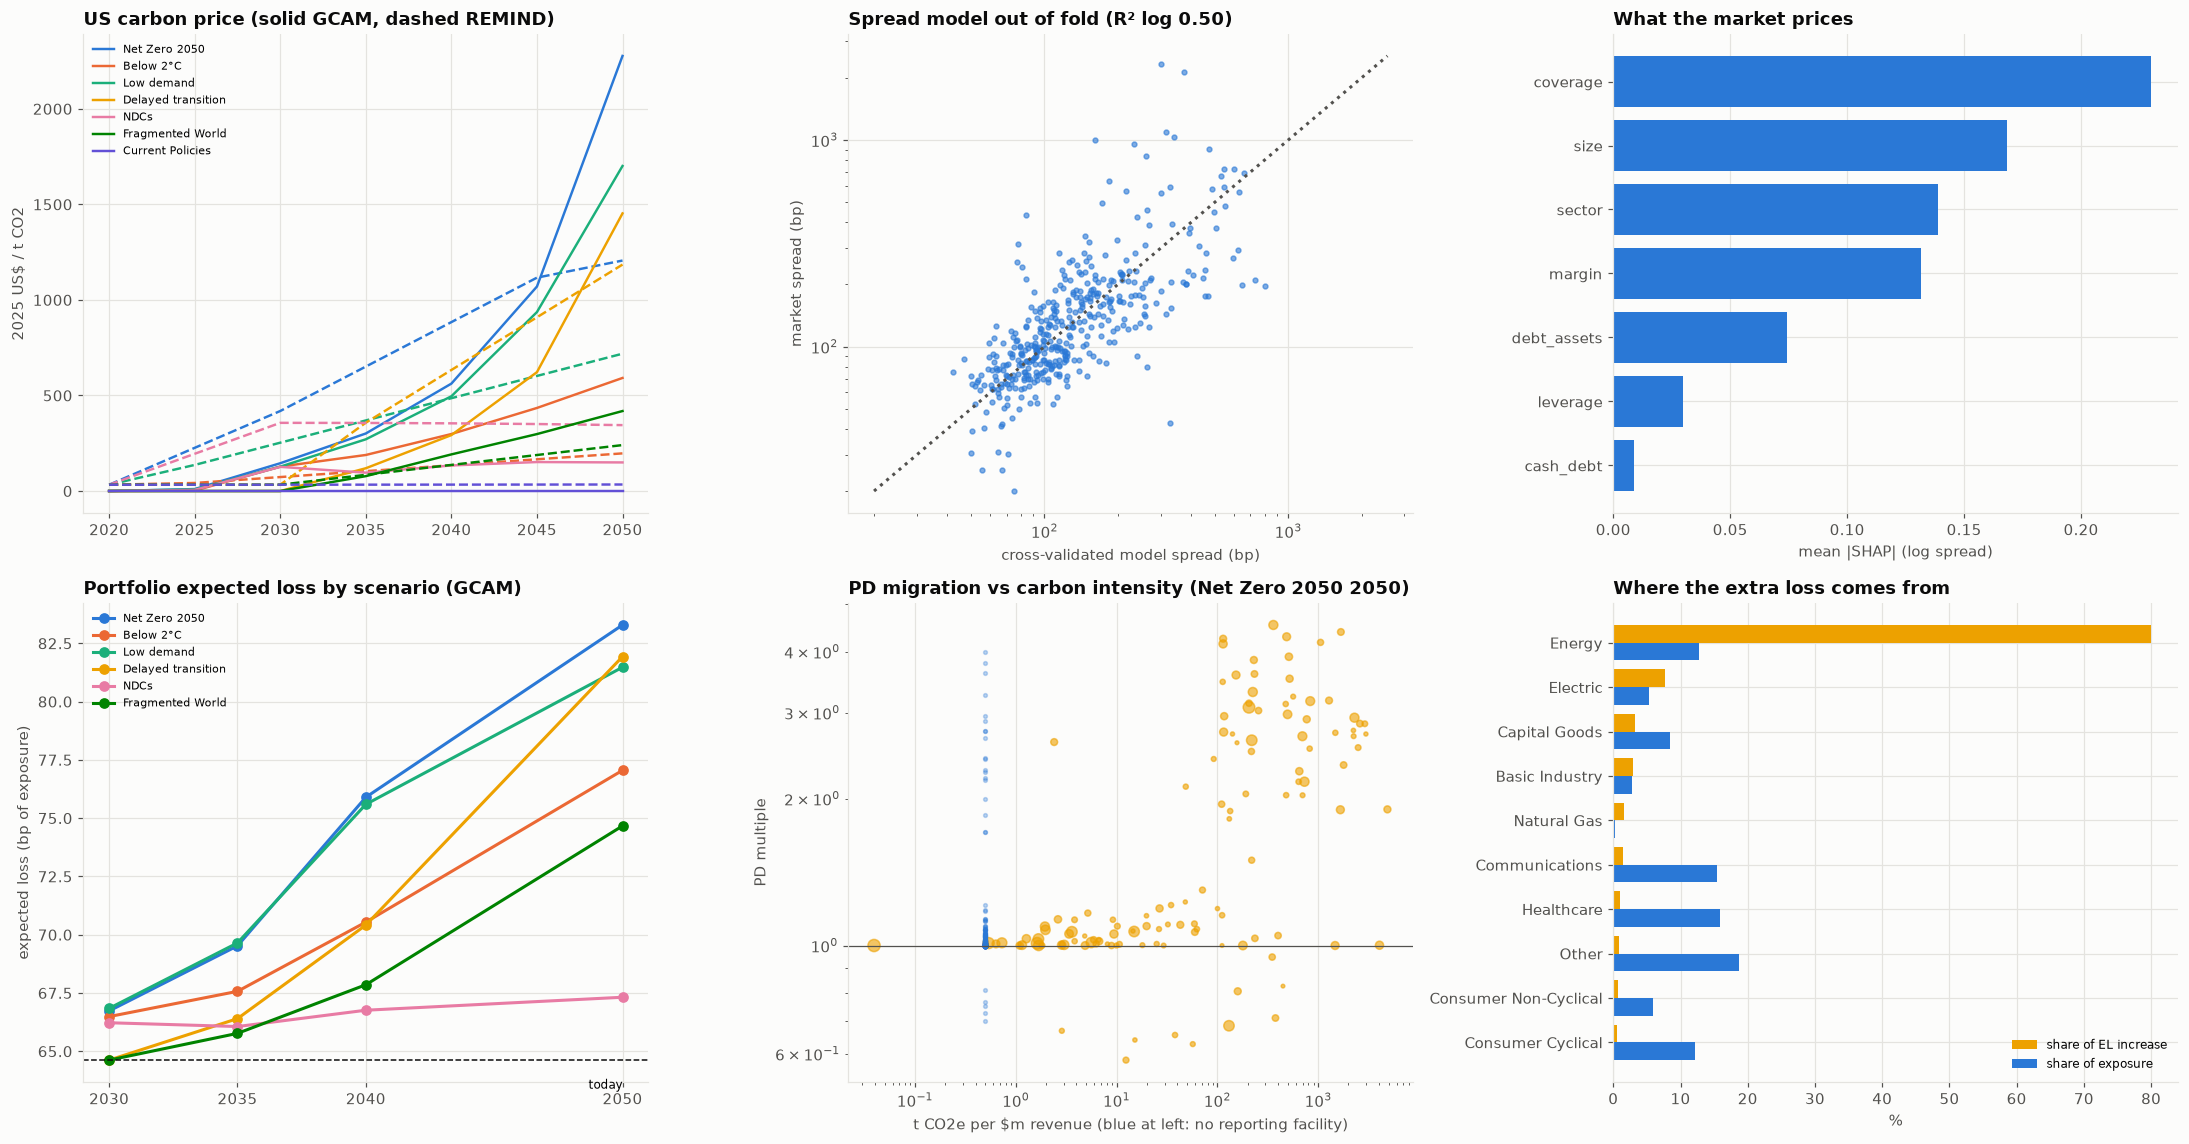

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10.5))
ax = axes[0, 0]
for (scen, c), m_ in zip(
    [(s_, c_) for s_, c_ in zip(SCEN + ["Current Policies"], PALETTE)],
    range(7),
):
    for model, ls in zip(NGFS_MODELS, ["-", "--"]):
        s_ = NG.loc[(model, scen), "Price|Carbon"] * USD10_TO_25
        s_ = s_[s_.index <= 2050]
        ax.plot(
            s_.index,
            s_.values,
            color=c,
            ls=ls,
            lw=1.6,
            label=scen if model.startswith("GCAM") else None,
        )
ax.set_ylabel("2025 US$ / t CO2")
ax.set_title("US carbon price (solid GCAM, dashed REMIND)")
ax.legend(fontsize=7)
ax = axes[0, 1]
ax.scatter(
    np.exp(cvp["LightGBM (monotonic)"].mean(0)),
    np.exp(y),
    s=10,
    color=PALETTE[0],
    alpha=0.6,
)
lim = [20, float(np.exp(y).max()) * 1.1]
ax.plot(lim, lim, color=INK_2, ls=":")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("cross-validated model spread (bp)")
ax.set_ylabel("market spread (bp)")
ax.set_title(f"Spread model out of fold (R² log {fit_tab.iloc[0, 0]:.2f})")
ax = axes[0, 2]
ax.barh(shap_imp.index[::-1], shap_imp.values[::-1], color=PALETTE[0])
ax.set_xlabel("mean |SHAP| (log spread)")
ax.set_title("What the market prices")
ax = axes[1, 0]
r_ = res[res["model"] == "GCAM 6.0 NGFS"].pivot(
    index="year", columns="scenario", values="EL (bp of exposure)"
)
for c_, col in zip(SCEN, PALETTE):
    ax.plot(r_.index, r_[c_], marker="o", color=col, label=c_)
ax.axhline(EL0, color=INK, ls="--", lw=1)
ax.text(HORIZONS[-1], EL0 - 0.8, "today", fontsize=8, ha="right", va="top")
ax.set_xticks(HORIZONS)
ax.set_ylabel("expected loss (bp of exposure)")
ax.set_title("Portfolio expected loss by scenario (GCAM)")
ax.legend(fontsize=7)
ax = axes[1, 1]
m_ = P["co2e"] > 0
ax.scatter(
    P.loc[m_, "intensity"],
    (P.loc[m_, "pd_worst"] / P.loc[m_, "pd0"]),
    s=np.sqrt(P.loc[m_, "exposure"] / 1e6) * 3,
    c=PALETTE[3],
    alpha=0.6,
)
ax.scatter(
    np.full((~m_).sum(), 0.5),
    P.loc[~m_, "pd_worst"] / P.loc[~m_, "pd0"],
    s=6,
    color=PALETTE[0],
    alpha=0.3,
)
ax.set_xscale("log")
ax.set_yscale("log")
ax.axhline(1, color=INK_2, lw=0.8)
ax.set_xlabel("t CO2e per $m revenue (blue at left: no reporting facility)")
ax.set_ylabel("PD multiple")
ax.set_title(
    f"PD migration vs carbon intensity ({worst['scenario']} {worst['year']})"
)
ax = axes[1, 2]
sa = sec_attr.sort_values("d_el_share")
sa = sa[sa["d_el_share"].abs() > 0.005]
yy = np.arange(len(sa))
ax.barh(
    yy + 0.2,
    sa["d_el_share"] * 100,
    0.4,
    color=PALETTE[3],
    label="share of EL increase",
)
ax.barh(
    yy - 0.2,
    sa["exposure_share"] * 100,
    0.4,
    color=PALETTE[0],
    label="share of exposure",
)
ax.set_yticks(yy)
ax.set_yticklabels(sa.index)
ax.set_xlabel("%")
ax.legend(fontsize=8)
ax.set_title("Where the extra loss comes from")
plt.tight_layout()
save_fig(fig, "01_transition_risk_portfolio")
plt.show()

In [11]:
dash = make_subplots(
    rows=1,
    cols=2,
    column_widths=[0.45, 0.55],
    subplot_titles=(
        "Expected loss by scenario and year (GCAM, bp)",
        "Issuer PD today vs stressed",
    ),
)
for c_, col in zip(SCEN, PALETTE):
    s_ = res[(res["model"] == "GCAM 6.0 NGFS") & (res["scenario"] == c_)]
    dash.add_trace(
        go.Scatter(
            x=s_["year"],
            y=s_["EL (bp of exposure)"],
            mode="lines+markers",
            name=c_,
            line=dict(color=col),
        ),
        1,
        1,
    )
dash.add_trace(
    go.Scatter(
        x=P["pd0"] * 100,
        y=P["pd_worst"] * 100,
        mode="markers",
        text=P["Name"] + " · " + P["sector"],
        marker=dict(
            size=np.clip(np.sqrt(P["exposure"] / 1e6), 3, 25),
            color=np.log10(P["intensity"] + 1),
            colorscale="YlOrRd",
            showscale=True,
            colorbar=dict(title="log10 t/$m", x=1.02),
        ),
        name="issuers",
        showlegend=False,
    ),
    1,
    2,
)
mx = float(P["pd_worst"].max() * 100)
dash.add_trace(
    go.Scatter(
        x=[0, mx],
        y=[0, mx],
        mode="lines",
        line=dict(dash="dot", color=INK_2),
        showlegend=False,
    ),
    1,
    2,
)
dash.update_xaxes(title_text="PD today (%)", type="log", row=1, col=2)
dash.update_yaxes(
    title_text=f"PD, {worst['scenario']} {worst['year']} (%)",
    type="log",
    row=1,
    col=2,
)
dash.update_layout(
    height=620,
    width=1300,
    template="simple_white",
    title=(
        "Climate transition stress of a US corporate bond portfolio (NGFS"
        " Phase 5)"
    ),
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 11. Reading the results and limitations

**Portfolio and data.**
- The two ETFs hold 3,069 bonds of 717 US non-financial issuers, $29bn in all. The median spread is 148 bp: 86 bp investment grade, 216 bp high yield.
- 81% of the exposure matches an SEC filer.
- After merging names that belong to the same filer and requiring complete statements, the model sample is 407 issuers and $23bn.
- GHGRP 2023 attributes 2.70 Gt CO₂e to 10,549 facilities. Through the parent-company shares, 126 portfolio issuers carry 901 Mt of reported Scope 1 emissions, concentrated in utilities (≈520 Mt) and energy (≈240 Mt).

**The spread model.**
- Fundamentals explain half of the cross-section of log spreads out of fold: R² 0.50, Spearman 0.76, median error 29 bp.
- The monotonic LightGBM and the ridge are almost tied. The relationship is close to log-linear, and most of the remaining dispersion is bond-specific (subordination, covenants, liquidity) or due to information not in the statements.
- SHAP ranks **interest coverage** first, then size, sector and margin. Coverage is exactly the channel through which a carbon cost reaches credit risk.

**Scenarios.**
- The two models disagree strongly on US carbon prices. For Net Zero 2050:
  - REMIND puts $419/t on 2030 already;
  - GCAM starts at $146/t but ends at $2,277/t in 2050.
- **Delayed Transition** is the classic "late and sudden" path: almost no carbon price until 2030, then $1,000–1,500/t by 2050.
- NDCs and Fragmented World stay moderate.

**Credit impact.**
- Portfolio expected loss rises from **65 bp today** to:
  - 66–67 bp in 2030 in most scenarios;
  - **76 bp in 2040** under GCAM Net Zero or Low Demand;
  - **81–83 bp in 2050**.
  That is a 25–30% increase, with up to 63 issuers seeing their PD at least double.
- The 99.9% credit VaR moves from 898 to about 980 bp in the 2040 orderly scenarios.
- REMIND front-loads the hit: Net Zero 2050 already gives 72 bp in 2030 and 78 bp in 2035.
- The comparison shows that **model uncertainty within one NGFS scenario is as large as the difference between scenarios**.

**Where the loss comes from.**
- **Energy is 13% of the exposure but 80% of the increase in expected loss.** Oil and gas demand falls in every transition scenario, and midstream and smaller exploration and production names are highly levered.
- Utilities hold the most emissions but generate only 8% of the increase:
  - regulated pass-through (70% assumed) protects them;
  - electricity demand *rises* in transition scenarios;
  - several utilities even improve.
- For most of the book (communications, healthcare, consumer) transition risk is negligible.
- Issuers without a reporting facility can still be hit through demand, such as gas compression and propane distributors.

**Limitations.**
- Only **Scope 1** emissions of US facilities above the GHGRP threshold are counted. Scope 2 and 3, foreign operations, and emitters below 25,000 t are missing. Firms with no matched facility have zero direct carbon cost.
- Parent-company names are matched to SEC filers by name, which is imperfect: the matching audit is in the outputs.
- The stress is static-balance-sheet with assumed pass-through rates, a triangle abatement-cost approximation and a fixed contribution margin. There is no adaptation, capital expenditure, refinancing or rating-driven selling.
- The spread model is cross-sectional and bounded by the range it was trained on: the most stressed issuers saturate near a 5–6% PD.
- PDs come from spreads with 40% recovery and a risk-neutral/physical ratio of 2. Correlation is a single ρ = 0.20.
- NGFS paths are model outputs, not forecasts. Only the two models with a US region are used.

In [12]:
match_audit.to_csv(OUT_DIR / "issuer_matching_audit.csv", index=False)
P[[
    "Name",
    "entity",
    "sector",
    "exposure",
    "spread_bp",
    "spread_model",
    "revenue",
    "ebitda",
    "debt",
    "co2e",
    "intensity",
    "pd0",
    "pd_worst",
]].to_csv(OUT_DIR / "issuer_emissions_and_pd.csv", index=False)
fit_tab.to_csv(OUT_DIR / "spread_model_cv.csv")
shap_imp.to_csv(OUT_DIR / "spread_model_shap.csv", header=["mean_abs_shap"])
res.to_csv(OUT_DIR / "scenario_results_by_model_year.csv", index=False)
cvar.to_csv(OUT_DIR / "credit_var_by_scenario.csv", index=False)
sec_attr.to_csv(OUT_DIR / "sector_attribution.csv")
cp_tab.to_csv(OUT_DIR / "ngfs_us_carbon_prices.csv")
print(
    "Outputs written:", ", ".join(sorted(p_.name for p_ in OUT_DIR.iterdir()))
)

Outputs written: 01_transition_risk_portfolio.png, credit_var_by_scenario.csv, dashboard.html, dashboard.png, issuer_emissions_and_pd.csv, issuer_matching_audit.csv, ngfs_us_carbon_prices.csv, scenario_results_by_model_year.csv, sector_attribution.csv, spread_model_cv.csv, spread_model_shap.csv


## References

### Finance and regulation

- Basel Committee on Banking Supervision. (2021). *Climate-related financial risks – measurement methodologies*. Bank for International Settlements. https://www.bis.org/bcbs/publ/d518.htm
- Battiston, S., Mandel, A., Monasterolo, I., Schütze, F., & Visentin, G. (2017). A climate stress-test of the financial system. *Nature Climate Change, 7*(4), 283–288. https://doi.org/10.1038/nclimate3255
- Bolton, P., & Kacperczyk, M. (2021). Do investors care about carbon risk? *Journal of Financial Economics, 142*(2), 517–549. https://doi.org/10.1016/j.jfineco.2021.05.008
- Seltzer, L. H., Starks, L., & Zhu, Q. (2022). *Climate regulatory risk and corporate bonds* (NBER Working Paper No. 29994). National Bureau of Economic Research. https://doi.org/10.3386/w29994
- Gordy, M. B. (2003). A risk-factor model foundation for ratings-based bank capital rules. *Journal of Financial Intermediation, 12*(3), 199–232. https://doi.org/10.1016/S1042-9573(03)00040-8

### Machine learning and deep learning

- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*. https://arxiv.org/abs/1705.07874
- Christen, P. (2012). *Data matching: Concepts and techniques for record linkage, entity resolution, and duplicate detection*. Springer. https://doi.org/10.1007/978-3-642-31164-2